# 08 — Project-brief required models and local explanations

This notebook closes the remaining mandatory items in the project brief without changing the frozen final policy or reopening model selection.

It provides:

- a consolidated validation table for the empirical baseline, Logistic Regression, Decision Tree and Random Forest across feature sets A-D;
- a small Decision Tree and three paths expressed in market variables;
- Random Forest impurity importance versus validation permutation importance;
- global and local SHAP explanations;
- LIME explanations for the same high-, low- and uncertain-probability orders across five random seeds;
- a same-order SHAP comparison across 5, 30 and 60 seconds.

All new model comparisons and explanations use training and validation data only. Notebook 06 remains the only final-test evaluation.


## Protocol

The baseline comparison reproduces notebook 04's fixed model settings. It does not supersede notebook 05's time-aware tuning or notebook 06's final test result. SHAP and LIME describe model behavior and must not be read as causal effects.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import subprocess
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_SEED = 42
HORIZONS = (5, 30, 60)
FEATURE_PERMUTATION_REPEATS = 15
LIME_SEEDS = (11, 22, 33, 44, 55)

project_root_override = os.environ.get("LIMIT_ORDER_PROJECT_ROOT")
PROJECT_ROOT = Path(project_root_override) if project_root_override else Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
RAW_DIR = PROJECT_ROOT / "data" / "raw"
RESULTS_DIR = Path(os.environ.get("LIMIT_ORDER_ARTIFACT_DIR", PROJECT_ROOT / "results"))
FIGURE_DIR = Path(os.environ.get("LIMIT_ORDER_FIGURE_DIR", PROJECT_ROOT / "reports" / "figures"))
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from brief_completion import (
    aggregate_transformed_values,
    lime_explanation_table,
    lime_seed_stability,
    positive_class_shap_values,
    random_forest_impurity_table,
    transformed_feature_mapping,
    tree_path_conditions,
)
from evaluation import expected_calibration_error
from explainability import individual_permutation_importance
from history_features import add_order_side_features, build_history_features
from modeling import (
    FEATURE_SETS,
    add_oriented_static_features,
    build_preprocessor,
)

analysis_source_commit = subprocess.check_output(
    ["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT, text=True
).strip()
workspace_status = subprocess.check_output(
    ["git", "status", "--porcelain"], cwd=PROJECT_ROOT, text=True
).strip()
brief_path = Path(os.environ.get(
    "LIMIT_ORDER_PROJECT_BRIEF",
    PROJECT_ROOT / "AI_Order_Execution_Project.pdf",
))
brief_sha256 = hashlib.sha256(brief_path.read_bytes()).hexdigest() if brief_path.exists() else None

assert workspace_status == "", "Worktree must be clean before the brief-completion analysis."
print("Analysis source commit:", analysis_source_commit)
print("Brief SHA-256:", brief_sha256)
print("Raw test target columns requested:", 0)


Analysis source commit: 3b78e7db6aa0f047d8e8a523f3721b0a9a2d531a
Brief SHA-256: de84f2e0bac18d6b078c0a2fa2b7ec57e325ad701c8b7b3d3015833907b163c5
Raw test target columns requested: 0


## Development data and historical features

Only the supplied train and validation rows are retained from the workbook. Historical features use the same validated pre-submission construction as notebooks 03 and 04.


In [2]:
excel_files = sorted(RAW_DIR.glob("*.xlsx"))
json_files = sorted(list(RAW_DIR.glob("*.json")) + list(RAW_DIR.glob("*.json.gz")))
assert len(excel_files) == 1
assert len(json_files) == 1
EXCEL_PATH = excel_files[0]
JSON_PATH = json_files[0]

orders = pd.read_excel(EXCEL_PATH, sheet_name="Orders", nrows=8_500)
orders["data_split_normalized"] = orders["data_split"].astype(str).str.lower()
assert len(orders) == 8_500
assert orders["data_split_normalized"].value_counts().to_dict() == {
    "train": 7_000,
    "validation": 1_500,
}
assert not orders["data_split_normalized"].eq("test").any()

history_started = time.perf_counter()
history_features = build_history_features(JSON_PATH)
history_seconds = time.perf_counter() - history_started
history_check_columns = [
    column for column in history_features if column.startswith("check_")
]
assert len(history_features) == 10_000
assert history_features["order_id"].is_unique
assert history_features["history_snapshot_count"].eq(50).all()
assert history_features[history_check_columns].all().all()

development = orders.merge(
    history_features,
    on="order_id",
    how="left",
    validate="one_to_one",
)
development = add_order_side_features(development)
development = add_oriented_static_features(development)
assert development[FEATURE_SETS["D_full_history"]].notna().all().all()

training_rows = development.loc[
    development["data_split_normalized"].eq("train")
].copy()
validation_rows = development.loc[
    development["data_split_normalized"].eq("validation")
].copy()

print("Development rows:", len(development))
print("Training / validation:", len(training_rows), len(validation_rows))
print("History build seconds:", round(history_seconds, 2))


Development rows: 8500
Training / validation: 7000 1500
History build seconds: 7.15


## Consolidated validation model and feature-set table

The empirical fill-rate baseline uses the training positive rate. All learned models use preprocessing fitted on training rows only. Metrics below are validation metrics at a fixed 0.5 threshold and are separate from the tuned final policy.


In [3]:
def model_factories():
    return {
        "logistic_regression": lambda: LogisticRegression(
            C=1.0,
            max_iter=3000,
            solver="lbfgs",
            random_state=RANDOM_SEED,
        ),
        "decision_tree": lambda: DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=50,
            random_state=RANDOM_SEED,
        ),
        "random_forest": lambda: RandomForestClassifier(
            n_estimators=250,
            min_samples_leaf=5,
            max_features="sqrt",
            n_jobs=-1,
            random_state=RANDOM_SEED,
        ),
    }


def complete_metrics(y_true, probability, threshold=0.5):
    y_true = np.asarray(y_true, dtype=int)
    probability = np.asarray(probability, dtype=float)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    return {
        "roc_auc": float(roc_auc_score(y_true, probability)),
        "pr_auc": float(average_precision_score(y_true, probability)),
        "brier_score": float(brier_score_loss(y_true, probability)),
        "ece_10": expected_calibration_error(y_true, probability, bins=10),
        "accuracy": float(accuracy_score(y_true, prediction)),
        "precision": float(precision_score(y_true, prediction, zero_division=0)),
        "recall": float(recall_score(y_true, prediction, zero_division=0)),
        "f1": float(f1_score(y_true, prediction, zero_division=0)),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }


validation_result_rows = []
fitted_models = {}
validation_probability_store = {}

for horizon in HORIZONS:
    eligibility = f"eligible_{horizon}s"
    target = f"target_fill_{horizon}s"
    train_h = training_rows.loc[training_rows[eligibility].eq(1)]
    validation_h = validation_rows.loc[validation_rows[eligibility].eq(1)]
    y_train = train_h[target].astype(int).to_numpy()
    y_validation = validation_h[target].astype(int).to_numpy()

    baseline_probability = float(y_train.mean())
    baseline_probabilities = np.full(len(y_validation), baseline_probability)
    validation_result_rows.append({
        "horizon_seconds": horizon,
        "feature_set": "baseline",
        "feature_count": 0,
        "model": "empirical_fill_rate",
        "threshold": 0.5,
        "eligible_validation_rows": len(y_validation),
        **complete_metrics(y_validation, baseline_probabilities),
    })

    for feature_set_name, features in FEATURE_SETS.items():
        for model_name, factory in model_factories().items():
            estimator = Pipeline([
                ("preprocessing", build_preprocessor(features)),
                ("model", factory()),
            ])
            estimator.fit(train_h[features], y_train)
            probability = estimator.predict_proba(validation_h[features])[:, 1]
            validation_result_rows.append({
                "horizon_seconds": horizon,
                "feature_set": feature_set_name,
                "feature_count": len(features),
                "model": model_name,
                "threshold": 0.5,
                "eligible_validation_rows": len(y_validation),
                **complete_metrics(y_validation, probability),
            })
            fitted_models[(horizon, feature_set_name, model_name)] = estimator
            validation_probability_store[(horizon, feature_set_name, model_name)] = {
                "order_id": validation_h["order_id"].to_numpy(),
                "target": y_validation.copy(),
                "probability": probability.copy(),
            }

validation_model_results = pd.DataFrame(validation_result_rows).sort_values(
    ["horizon_seconds", "feature_set", "model"]
)

display(
    validation_model_results[
        [
            "horizon_seconds", "feature_set", "model", "roc_auc", "pr_auc",
            "brier_score", "accuracy", "precision", "recall", "f1",
        ]
    ].round(4)
)
print("Learned models fitted:", len(fitted_models))
print("Raw test predictions produced:", 0)


,horizon_seconds,feature_set,model,roc_auc,pr_auc,brier_score,accuracy,precision,recall,f1
2,5,A_order,decision_tree,0.6333,0.1698,0.0886,0.8976,0.0000,0.0000,0.0000
1,5,A_order,logistic_regression,0.6751,0.2377,0.0879,0.8976,0.0000,0.0000,0.0000
3,5,A_order,random_forest,0.6329,0.2222,0.0887,0.8990,1.0000,0.0134,0.0265
5,5,B_order_lob,decision_tree,0.6303,0.1853,0.0879,0.8976,0.0000,0.0000,0.0000
4,5,B_order_lob,logistic_regression,0.6645,0.2479,0.0873,0.8976,0.0000,0.0000,0.0000
6,5,B_order_lob,random_forest,0.6365,0.2326,0.0937,0.8976,0.0000,0.0000,0.0000
8,5,C_order_lob_flow,decision_tree,0.6187,0.1922,0.0877,0.8976,0.5000,0.0268,0.0510
7,5,C_order_lob_flow,logistic_regression,0.6679,0.2322,0.0877,0.8976,0.0000,0.0000,0.0000
9,5,C_order_lob_flow,random_forest,0.6331,0.2352,0.0941,0.8976,0.0000,0.0000,0.0000
11,5,D_full_history,decision_tree,0.5925,0.1644,0.0893,0.8976,0.5000,0.0268,0.0510


Learned models fitted: 36
Raw test predictions produced: 0


In [4]:
baseline_rows = validation_model_results.loc[
    validation_model_results["model"].eq("empirical_fill_rate")
].set_index("horizon_seconds")

rq1_rows = []
for horizon in HORIZONS:
    for model_name in ("logistic_regression", "decision_tree", "random_forest"):
        best = (
            validation_model_results.loc[
                validation_model_results["horizon_seconds"].eq(horizon)
                & validation_model_results["model"].eq(model_name)
            ]
            .sort_values(["pr_auc", "brier_score"], ascending=[False, True])
            .iloc[0]
        )
        baseline = baseline_rows.loc[horizon]
        rq1_rows.append({
            "horizon_seconds": horizon,
            "model": model_name,
            "best_feature_set": best["feature_set"],
            "pr_auc": best["pr_auc"],
            "baseline_pr_auc": baseline["pr_auc"],
            "pr_auc_gain": best["pr_auc"] - baseline["pr_auc"],
            "roc_auc": best["roc_auc"],
            "baseline_roc_auc": baseline["roc_auc"],
            "brier_score": best["brier_score"],
            "baseline_brier_score": baseline["brier_score"],
        })

rq1_model_comparison = pd.DataFrame(rq1_rows)
display(rq1_model_comparison.round(4))


,horizon_seconds,model,best_feature_set,pr_auc,baseline_pr_auc,pr_auc_gain,roc_auc,baseline_roc_auc,brier_score,baseline_brier_score
0,5,logistic_regression,B_order_lob,0.2479,0.1024,0.1455,0.6645,0.5,0.0873,0.0919
1,5,decision_tree,C_order_lob_flow,0.1922,0.1024,0.0898,0.6187,0.5,0.0877,0.0919
2,5,random_forest,C_order_lob_flow,0.2352,0.1024,0.1328,0.6331,0.5,0.0941,0.0919
3,30,logistic_regression,B_order_lob,0.5993,0.3958,0.2036,0.6744,0.5,0.2179,0.2396
4,30,decision_tree,C_order_lob_flow,0.5400,0.3958,0.1443,0.6531,0.5,0.2204,0.2396
5,30,random_forest,D_full_history,0.5976,0.3958,0.2019,0.6710,0.5,0.2197,0.2396
6,60,logistic_regression,C_order_lob_flow,0.7864,0.6140,0.1724,0.6929,0.5,0.2164,0.2374
7,60,decision_tree,B_order_lob,0.7294,0.6140,0.1153,0.6559,0.5,0.2176,0.2374
8,60,random_forest,C_order_lob_flow,0.7891,0.6140,0.1750,0.6812,0.5,0.2164,0.2374


## Small Decision Tree and market paths

The baseline table retains the depth-4 Decision Tree from notebook 04. For readable rules, a separate depth-2 explanation tree is fitted on the same 30-second C feature set. Three validation orders are selected mechanically from the corresponding Random Forest: highest probability, lowest probability and closest to 0.5 among orders eligible at all three horizons.


,case_type,order_id,target_fill_30s,rf_30_probability
0,high_probability,ORD008229,0.0,0.8445
1,low_probability,ORD008395,0.0,0.1889
2,uncertain,ORD007710,1.0,0.5003


,case_type,order_id,depth,market_condition,tree_leaf_probability
0,high_probability,ORD008229,0,queue_ahead_qty <= 250.5,0.739965
1,high_probability,ORD008229,1,aggressive_trade_volume_against_order_10s > 248,0.739965
2,low_probability,ORD008395,0,queue_ahead_qty > 250.5,0.142857
3,low_probability,ORD008395,1,price_distance_ticks > 1.5,0.142857
4,uncertain,ORD007710,0,queue_ahead_qty <= 250.5,0.496341
5,uncertain,ORD007710,1,aggressive_trade_volume_against_order_10s <= 248,0.496341


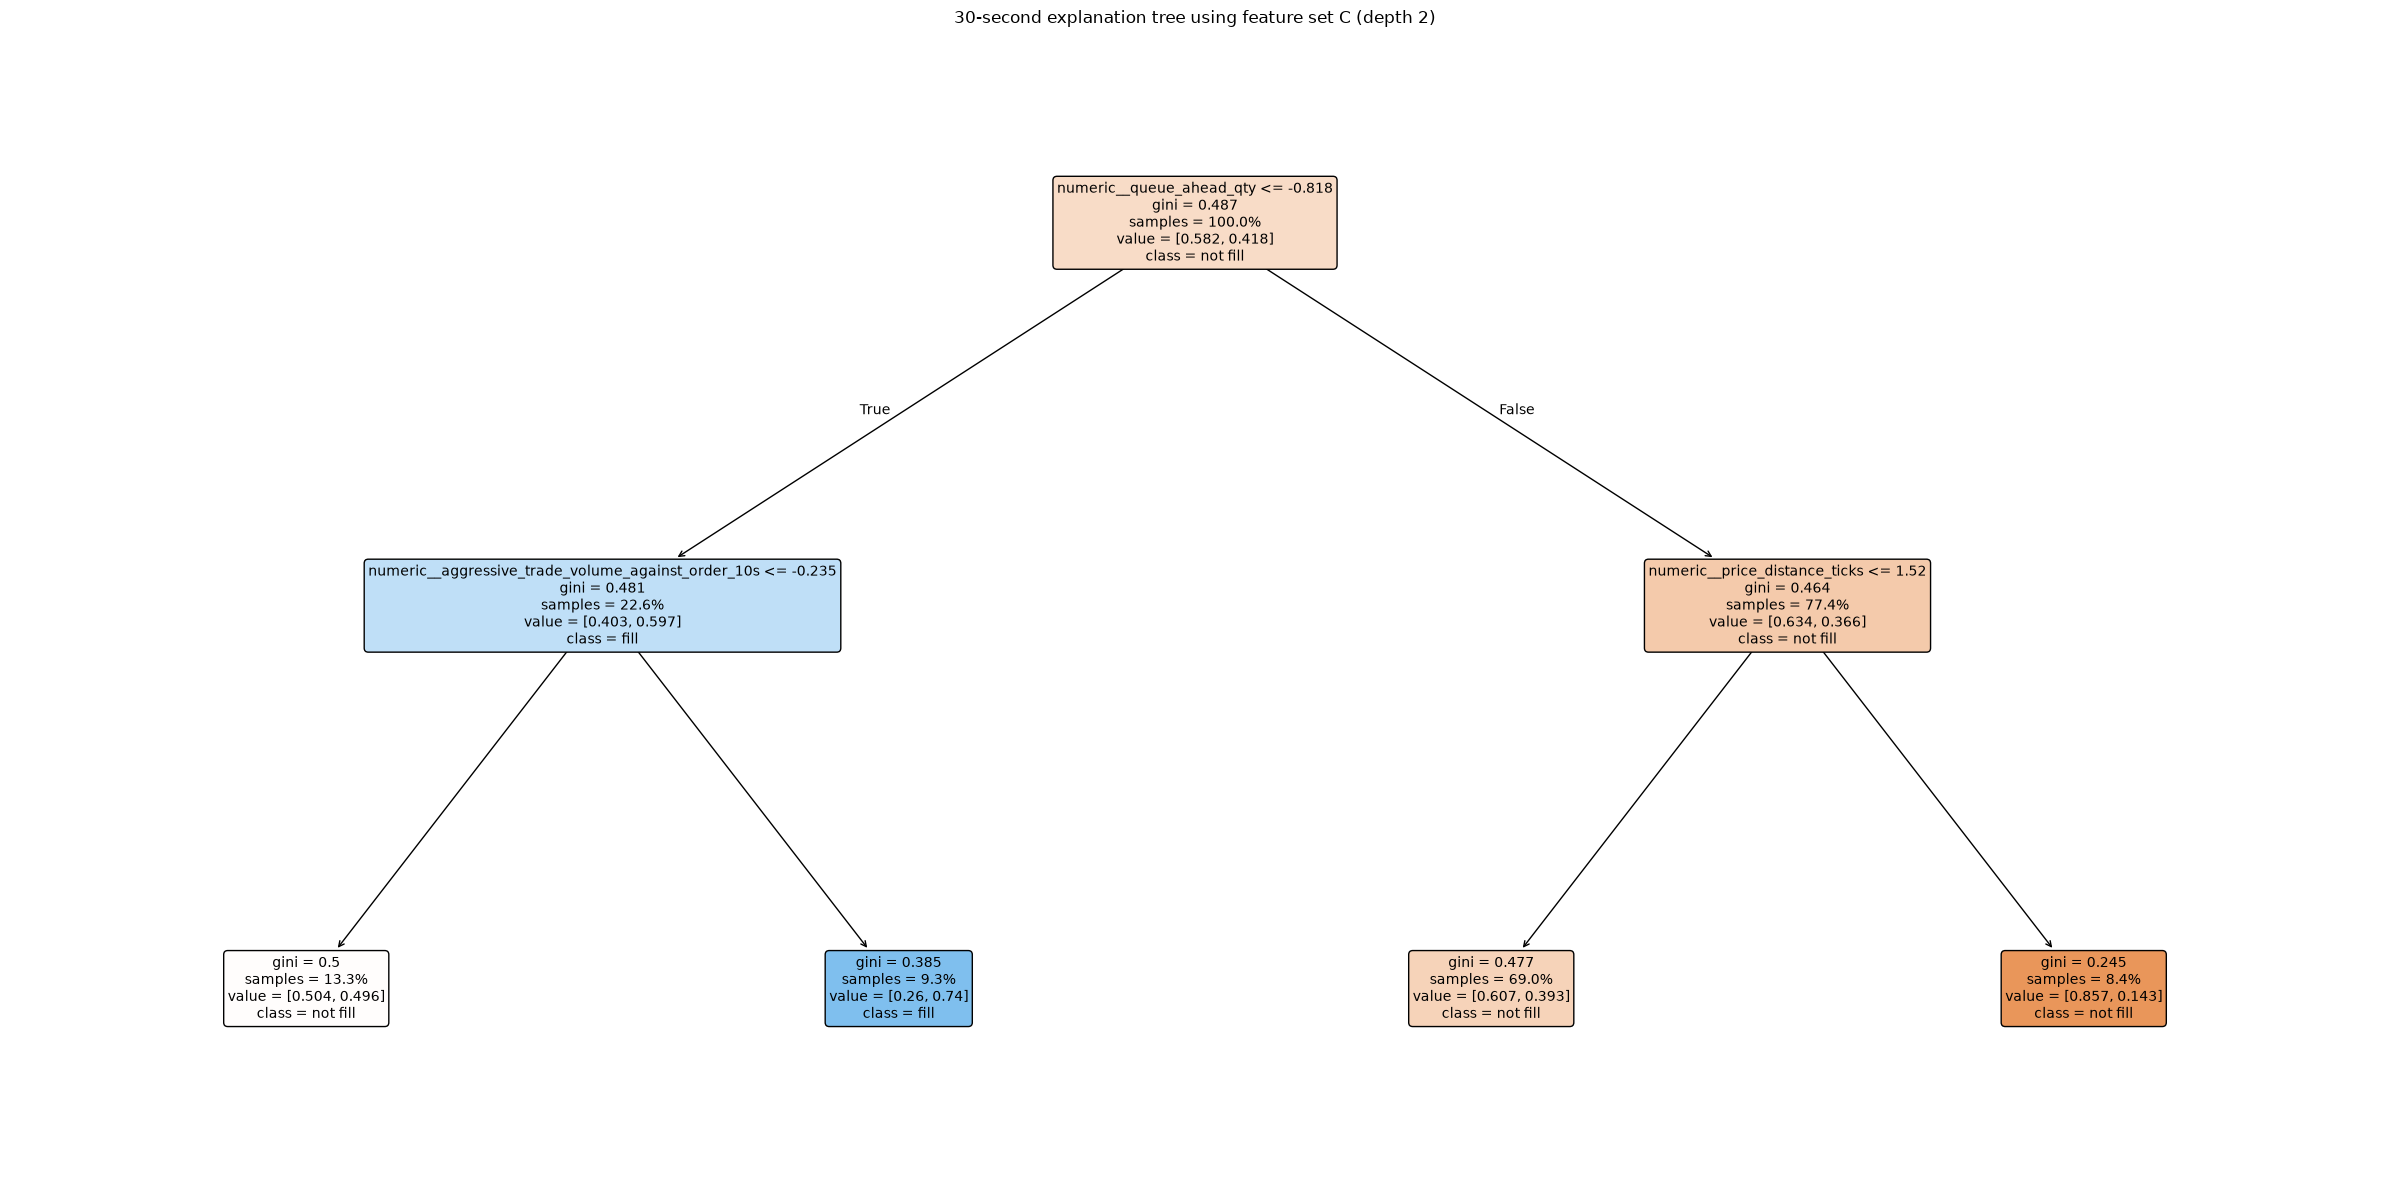

In [5]:
common_validation = validation_rows.loc[
    validation_rows[[f"eligible_{h}s" for h in HORIZONS]].eq(1).all(axis=1)
].copy()
rf_30 = fitted_models[(30, "C_order_lob_flow", "random_forest")]
features_c = FEATURE_SETS["C_order_lob_flow"]
common_validation["rf_30_probability"] = rf_30.predict_proba(
    common_validation[features_c]
)[:, 1]

selected_case_rows = []
case_specs = [
    ("high_probability", "rf_30_probability", False),
    ("low_probability", "rf_30_probability", True),
]
for case_type, column, ascending in case_specs:
    row = common_validation.sort_values(column, ascending=ascending).iloc[0]
    selected_case_rows.append({"case_type": case_type, **row.to_dict()})

remaining = common_validation.loc[
    ~common_validation["order_id"].isin(
        [row["order_id"] for row in selected_case_rows]
    )
].copy()
remaining["distance_to_half"] = (remaining["rf_30_probability"] - 0.5).abs()
uncertain_row = remaining.sort_values("distance_to_half").iloc[0]
selected_case_rows.append({"case_type": "uncertain", **uncertain_row.to_dict()})
selected_cases = pd.DataFrame(selected_case_rows)

train_30_for_tree = training_rows.loc[training_rows["eligible_30s"].eq(1)]
tree_30 = Pipeline([
    ("preprocessing", build_preprocessor(features_c)),
    ("model", DecisionTreeClassifier(
        max_depth=2,
        min_samples_leaf=100,
        random_state=RANDOM_SEED,
    )),
])
tree_30.fit(
    train_30_for_tree[features_c],
    train_30_for_tree["target_fill_30s"].astype(int),
)
tree_path_rows = []
for case in selected_cases.to_dict("records"):
    case_frame = pd.DataFrame([case])
    conditions, leaf_id, leaf_probability = tree_path_conditions(
        tree_30,
        case_frame[features_c],
    )
    for condition in conditions:
        tree_path_rows.append({
            "case_type": case["case_type"],
            "order_id": case["order_id"],
            "target_fill_30s": int(case["target_fill_30s"]),
            "rf_probability_30s": float(case["rf_30_probability"]),
            "tree_leaf_id": leaf_id,
            "tree_leaf_probability": leaf_probability,
            **condition,
        })

decision_tree_paths = pd.DataFrame(tree_path_rows)
display(
    selected_cases[
        ["case_type", "order_id", "target_fill_30s", "rf_30_probability"]
    ].round(4)
)
display(
    decision_tree_paths[
        [
            "case_type", "order_id", "depth", "market_condition",
            "tree_leaf_probability",
        ]
    ]
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
tree_preprocessing = tree_30.named_steps["preprocessing"]
tree_model = tree_30.named_steps["model"]
fig, ax = plt.subplots(figsize=(24, 12))
plot_tree(
    tree_model,
    feature_names=tree_preprocessing.get_feature_names_out(),
    class_names=["not fill", "fill"],
    filled=True,
    rounded=True,
    proportion=True,
    precision=3,
    ax=ax,
)
ax.set_title("30-second explanation tree using feature set C (depth 2)")
fig.tight_layout()
tree_figure_path = FIGURE_DIR / "brief_decision_tree_30s.png"
fig.savefig(tree_figure_path, dpi=160, bbox_inches="tight")
plt.show()


## Random Forest impurity versus permutation importance

Impurity importance is internal to the fitted forest and can favor continuous or highly variable predictors. Permutation importance measures the validation PR-AUC decrease when an original input column is shuffled. The two scales are compared by rank, top-10 overlap and Spearman correlation.


,horizon_seconds,spearman_rank_correlation,top_10_overlap_count,top_10_jaccard
0,5,-0.1127,3,0.1765
1,30,-0.0573,4,0.2500
2,60,0.3489,8,0.6667


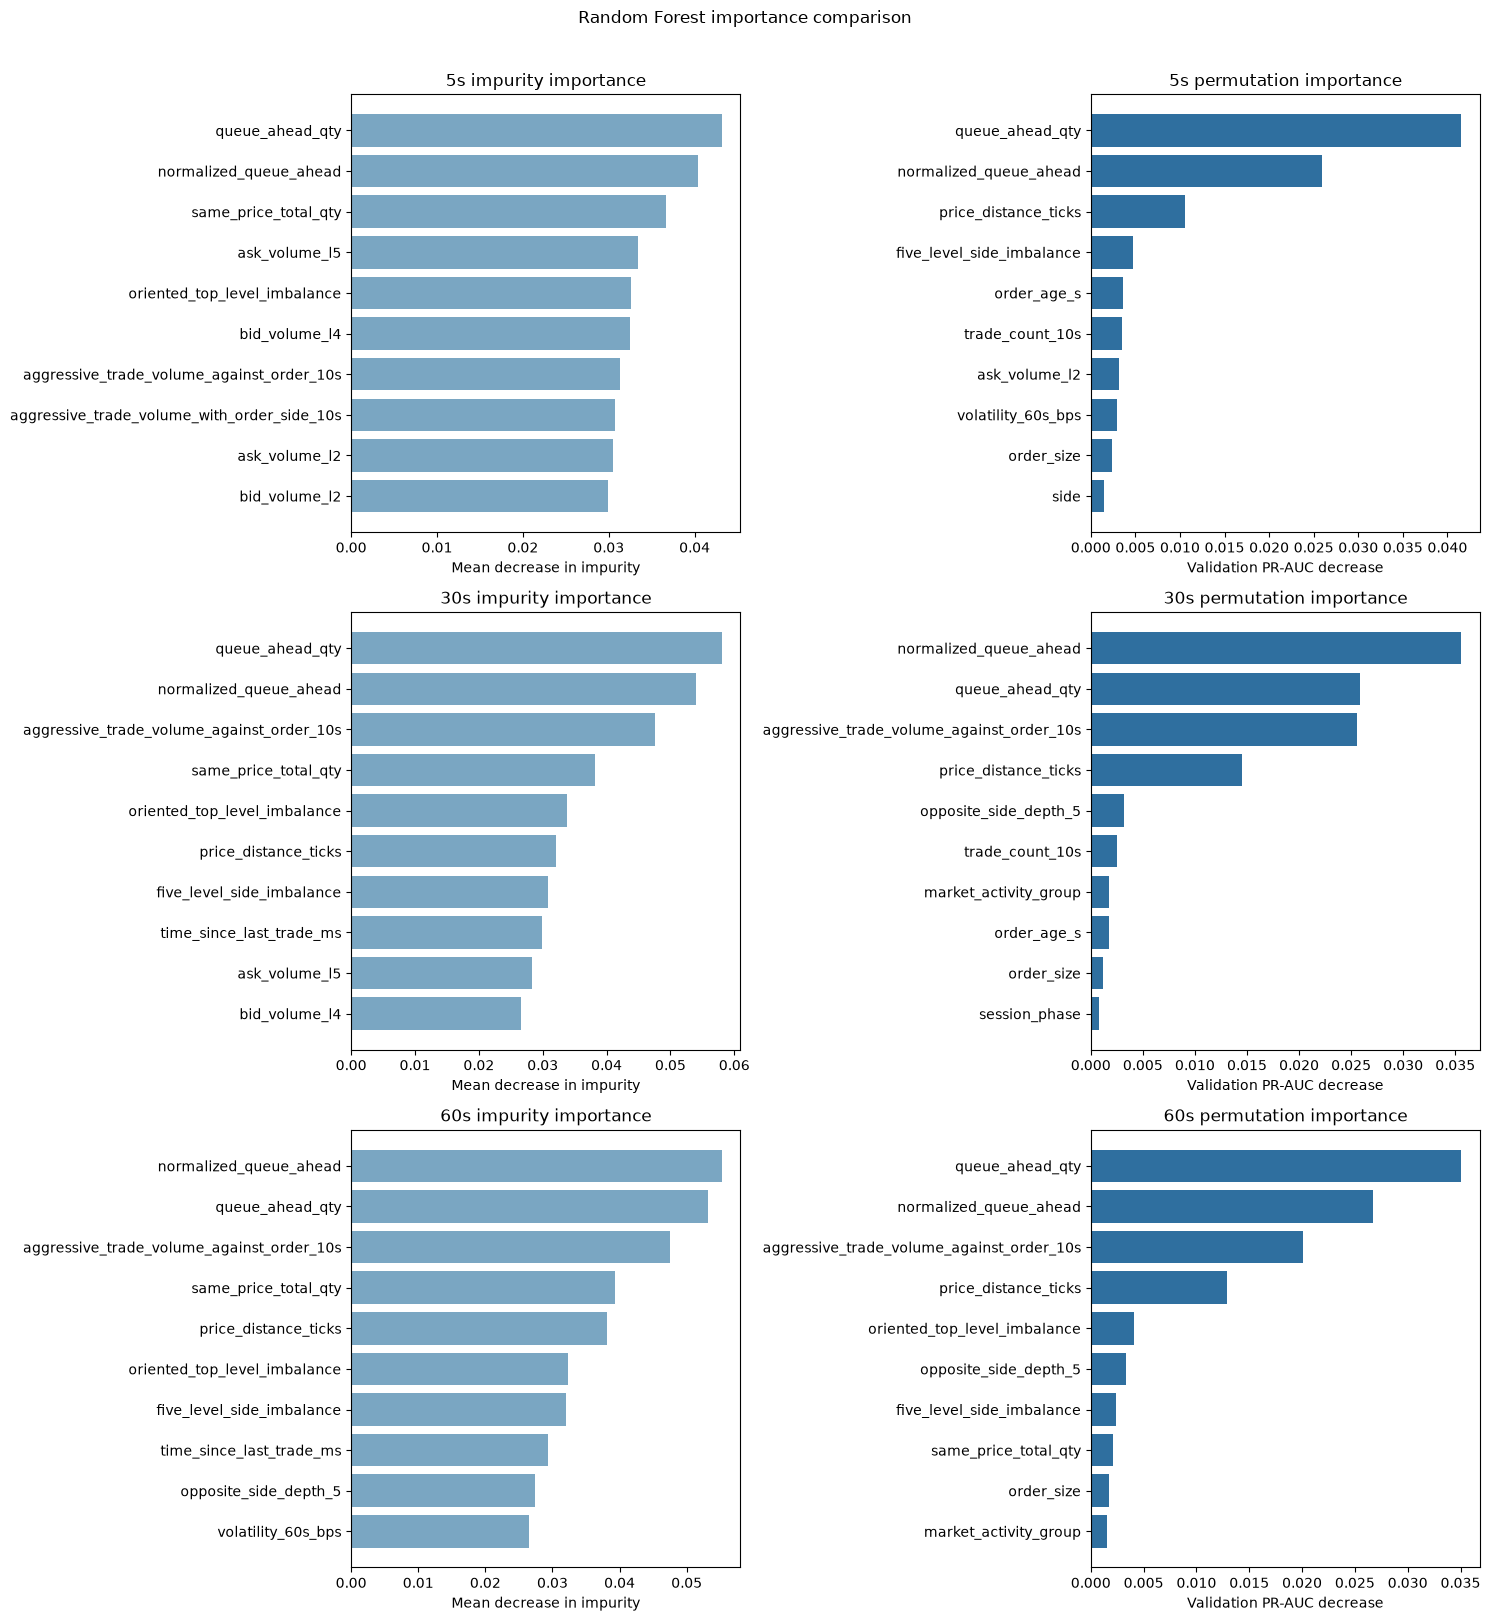

In [6]:
rf_importance_rows = []
rf_agreement_rows = []

for horizon in HORIZONS:
    eligibility = f"eligible_{horizon}s"
    target = f"target_fill_{horizon}s"
    validation_h = validation_rows.loc[validation_rows[eligibility].eq(1)]
    estimator = fitted_models[(horizon, "C_order_lob_flow", "random_forest")]

    impurity = random_forest_impurity_table(estimator)
    permutation = individual_permutation_importance(
        estimator,
        validation_h,
        validation_h[target].astype(int),
        features_c,
        random_seed=RANDOM_SEED + horizon,
        repeats=FEATURE_PERMUTATION_REPEATS,
    ).rename(columns={
        "feature": "original_feature",
        "pr_auc_decrease_mean": "permutation_pr_auc_decrease_mean",
        "pr_auc_decrease_std": "permutation_pr_auc_decrease_std",
        "pr_auc_decrease_ci_low": "permutation_ci_low",
        "pr_auc_decrease_ci_high": "permutation_ci_high",
    })

    comparison = impurity.merge(
        permutation[
            [
                "original_feature", "permutation_pr_auc_decrease_mean",
                "permutation_pr_auc_decrease_std", "permutation_ci_low",
                "permutation_ci_high",
            ]
        ],
        on="original_feature",
        how="outer",
        validate="one_to_one",
    ).fillna(0.0)
    comparison["horizon_seconds"] = horizon
    comparison["impurity_rank"] = comparison["impurity_importance"].rank(
        ascending=False, method="min"
    )
    comparison["permutation_rank"] = comparison[
        "permutation_pr_auc_decrease_mean"
    ].rank(ascending=False, method="min")
    rf_importance_rows.append(comparison)

    top_impurity = set(
        comparison.nlargest(10, "impurity_importance")["original_feature"]
    )
    top_permutation = set(
        comparison.nlargest(10, "permutation_pr_auc_decrease_mean")["original_feature"]
    )
    rf_agreement_rows.append({
        "horizon_seconds": horizon,
        "spearman_rank_correlation": float(
            comparison["impurity_rank"].corr(
                comparison["permutation_rank"], method="spearman"
            )
        ),
        "top_10_overlap_count": len(top_impurity & top_permutation),
        "top_10_jaccard": len(top_impurity & top_permutation) / len(top_impurity | top_permutation),
    })

rf_importance_comparison = pd.concat(rf_importance_rows, ignore_index=True)
rf_importance_agreement = pd.DataFrame(rf_agreement_rows)
display(rf_importance_agreement.round(4))

fig, axes = plt.subplots(3, 2, figsize=(15, 16))
for row_number, horizon in enumerate(HORIZONS):
    horizon_data = rf_importance_comparison.loc[
        rf_importance_comparison["horizon_seconds"].eq(horizon)
    ]
    top_impurity = horizon_data.nlargest(10, "impurity_importance").sort_values(
        "impurity_importance"
    )
    top_permutation = horizon_data.nlargest(
        10, "permutation_pr_auc_decrease_mean"
    ).sort_values("permutation_pr_auc_decrease_mean")

    axes[row_number, 0].barh(
        top_impurity["original_feature"],
        top_impurity["impurity_importance"],
        color="#7aa6c2",
    )
    axes[row_number, 0].set_title(f"{horizon}s impurity importance")
    axes[row_number, 0].set_xlabel("Mean decrease in impurity")

    axes[row_number, 1].barh(
        top_permutation["original_feature"],
        top_permutation["permutation_pr_auc_decrease_mean"],
        color="#2f6f9f",
    )
    axes[row_number, 1].set_title(f"{horizon}s permutation importance")
    axes[row_number, 1].set_xlabel("Validation PR-AUC decrease")

fig.suptitle("Random Forest importance comparison", y=1.01)
fig.tight_layout()
rf_importance_figure_path = FIGURE_DIR / "brief_rf_importance_comparison.png"
fig.savefig(rf_importance_figure_path, dpi=170, bbox_inches="tight")
plt.show()


## Global SHAP importance

Tree SHAP values are computed in probability space using 100 deterministic training-background rows and up to 300 validation rows per horizon. One-hot contributions are aggregated back to their original input variable.


 48%|==========          | 286/600 [00:11<00:12]       

 52%|===========         | 315/600 [00:12<00:10]       

 57%|===========         | 343/600 [00:13<00:09]       

 62%|============        | 371/600 [00:14<00:08]       

 67%|=============       | 400/600 [00:15<00:07]       

...

 88%|==================  | 528/600 [00:25<00:03]       

 92%|==================  | 550/600 [00:26<00:02]       

 95%|=================== | 571/600 [00:27<00:01]       

 99%|===================| 593/600 [00:28<00:00]       

,original_feature,mean_absolute_shap_probability,horizon_seconds
0,queue_ahead_qty,0.01393,5
1,price_distance_ticks,0.01157,5
2,same_price_total_qty,0.00839,5
3,mid_price,0.00824,5
4,microprice,0.00721,5
5,normalized_queue_ahead,0.00711,5
6,ask_price_l1,0.00709,5
7,ask_price_l2,0.00633,5
8,bid_price_l5,0.00596,5
9,ask_price_l3,0.00557,5


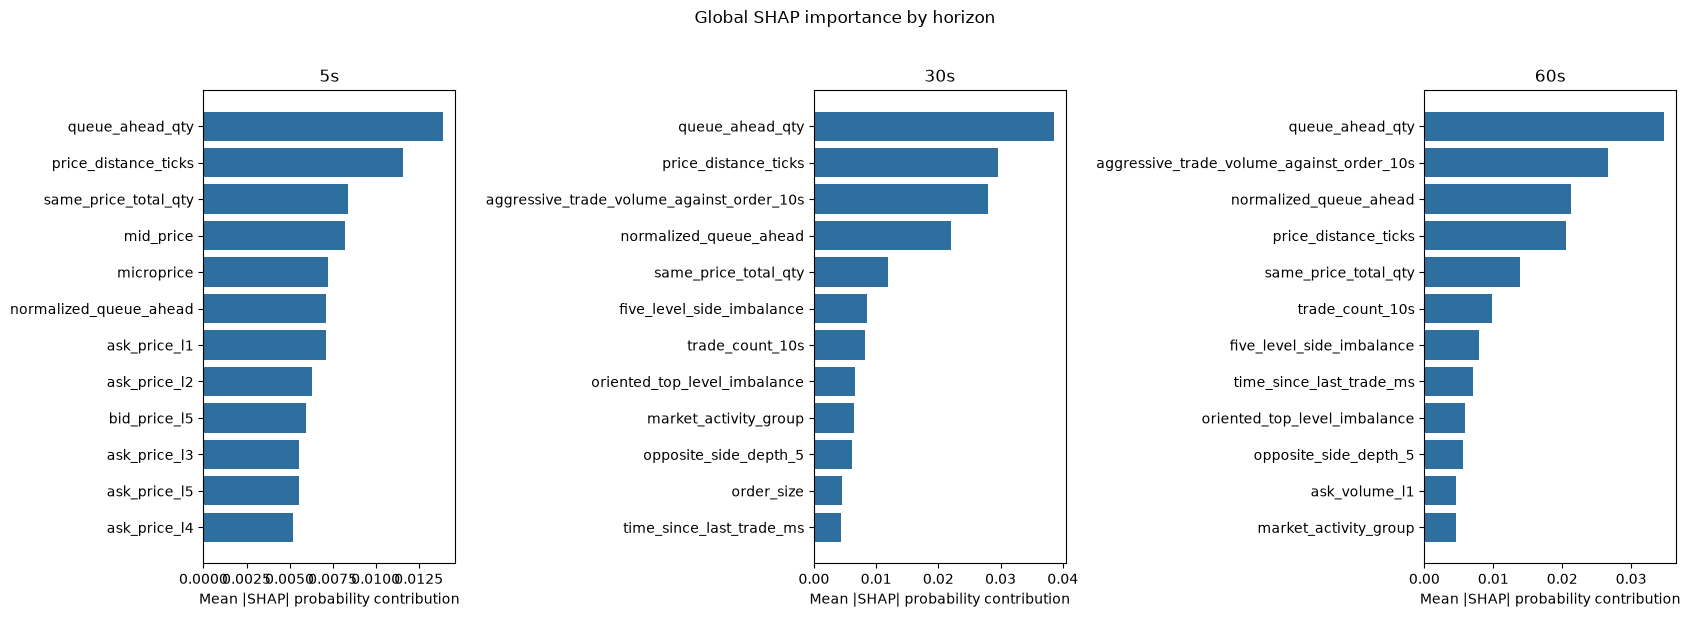

In [7]:
shap_explainers = {}
shap_global_rows = []
shap_context = {}

for horizon in HORIZONS:
    eligibility = f"eligible_{horizon}s"
    target = f"target_fill_{horizon}s"
    train_h = training_rows.loc[training_rows[eligibility].eq(1)]
    validation_h = validation_rows.loc[validation_rows[eligibility].eq(1)]
    estimator = fitted_models[(horizon, "C_order_lob_flow", "random_forest")]
    preprocessing = estimator.named_steps["preprocessing"]
    forest = estimator.named_steps["model"]
    mapping = transformed_feature_mapping(preprocessing)

    background_frame = train_h.sample(
        n=min(100, len(train_h)),
        random_state=RANDOM_SEED + horizon,
    )
    explanation_frame = validation_h.sample(
        n=min(300, len(validation_h)),
        random_state=RANDOM_SEED + 100 + horizon,
    )
    background = preprocessing.transform(background_frame[features_c])
    explanation_values = preprocessing.transform(explanation_frame[features_c])

    explainer = shap.TreeExplainer(
        forest,
        data=background,
        feature_perturbation="interventional",
        model_output="probability",
    )
    explanation = explainer(explanation_values)
    values, base_values = positive_class_shap_values(explanation)
    mean_absolute = np.abs(values).mean(axis=0)
    global_table = aggregate_transformed_values(
        mapping,
        mean_absolute,
        "mean_absolute_shap_probability",
    )
    global_table["horizon_seconds"] = horizon
    shap_global_rows.append(global_table)
    shap_explainers[horizon] = explainer
    shap_context[horizon] = {
        "preprocessing": preprocessing,
        "forest": forest,
        "mapping": mapping,
        "background_rows": len(background_frame),
        "explained_rows": len(explanation_frame),
        "mean_base_probability": float(np.mean(base_values)),
    }

shap_global_importance = pd.concat(shap_global_rows, ignore_index=True)
display(
    shap_global_importance.sort_values(
        ["horizon_seconds", "mean_absolute_shap_probability"],
        ascending=[True, False],
    ).groupby("horizon_seconds").head(10).round(5)
)

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, horizon in zip(axes, HORIZONS):
    top = (
        shap_global_importance.loc[
            shap_global_importance["horizon_seconds"].eq(horizon)
        ]
        .nlargest(12, "mean_absolute_shap_probability")
        .sort_values("mean_absolute_shap_probability")
    )
    ax.barh(
        top["original_feature"],
        top["mean_absolute_shap_probability"],
        color="#2f6f9f",
    )
    ax.set_title(f"{horizon}s")
    ax.set_xlabel("Mean |SHAP| probability contribution")

fig.suptitle("Global SHAP importance by horizon", y=1.02)
fig.tight_layout()
shap_global_figure_path = FIGURE_DIR / "brief_shap_global_importance.png"
fig.savefig(shap_global_figure_path, dpi=170, bbox_inches="tight")
plt.show()


## Local SHAP explanations for the three 30-second cases

Signed SHAP contributions are summed from transformed columns back to original variables. Positive values increase the Random Forest fill probability relative to the background expectation.


,horizon_seconds,case_type,order_id,target_fill,predicted_probability,base_probability,rank,original_feature,shap_probability_contribution,abs_shap
0,30,high_probability,ORD008229,0,0.84446,0.45132,1,queue_ahead_qty,0.11432,0.11432
1,30,high_probability,ORD008229,0,0.84446,0.45132,2,normalized_queue_ahead,0.09491,0.09491
2,30,high_probability,ORD008229,0,0.84446,0.45132,3,aggressive_trade_volume_against_order_10s,0.04681,0.04681
3,30,high_probability,ORD008229,0,0.84446,0.45132,4,same_price_total_qty,0.03919,0.03919
4,30,high_probability,ORD008229,0,0.84446,0.45132,5,oriented_top_level_imbalance,0.02865,0.02865
5,30,high_probability,ORD008229,0,0.84446,0.45132,6,bid_volume_l1,0.02453,0.02453
6,30,high_probability,ORD008229,0,0.84446,0.45132,7,price_distance_ticks,0.01656,0.01656
7,30,high_probability,ORD008229,0,0.84446,0.45132,8,five_level_side_imbalance,0.01528,0.01528
8,30,high_probability,ORD008229,0,0.84446,0.45132,9,same_side_depth_5,0.00944,0.00944
9,30,high_probability,ORD008229,0,0.84446,0.45132,10,market_activity_group,-0.00731,0.00731


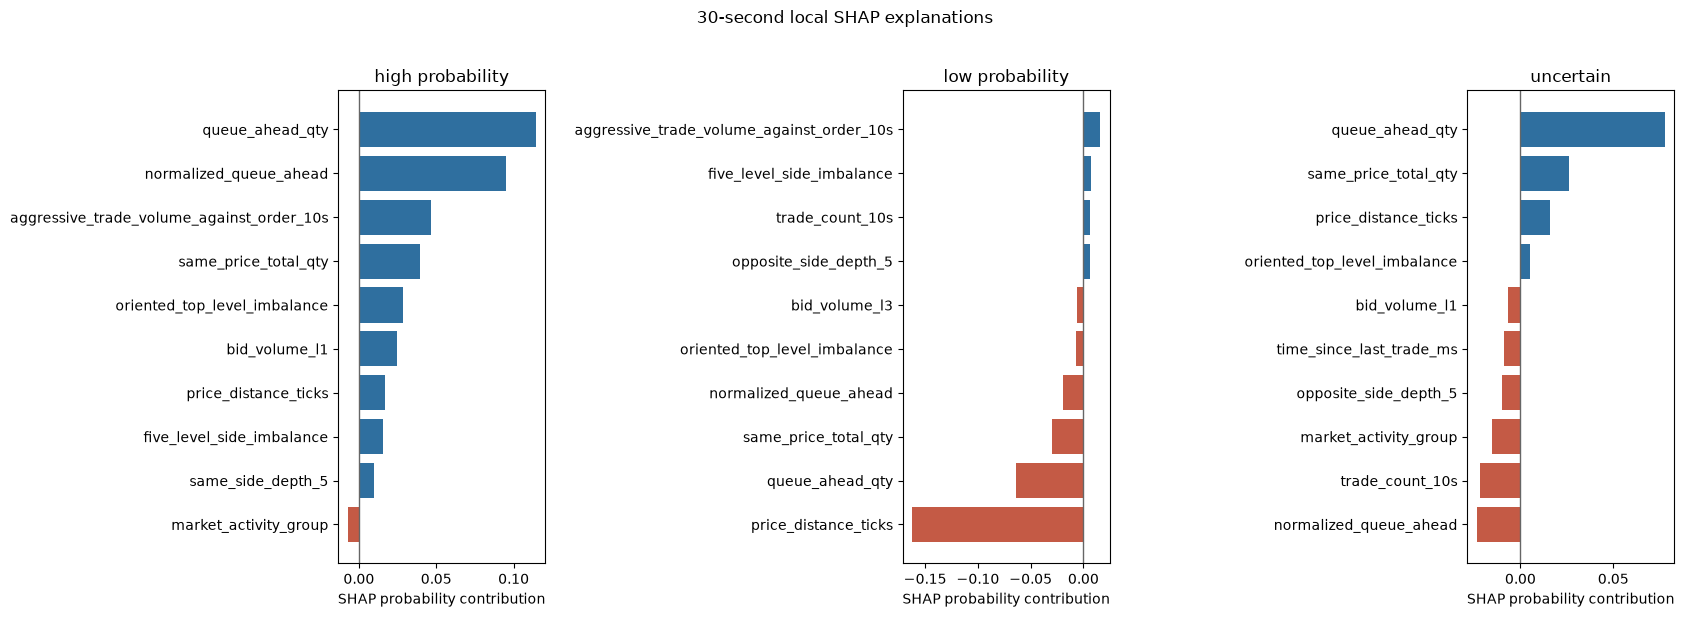

In [8]:
context_30 = shap_context[30]
case_30_transformed = context_30["preprocessing"].transform(
    selected_cases[features_c]
)
case_30_explanation = shap_explainers[30](case_30_transformed)
case_30_values, case_30_base_values = positive_class_shap_values(
    case_30_explanation
)

shap_local_rows = []
for case_index, case in enumerate(selected_cases.to_dict("records")):
    aggregated = aggregate_transformed_values(
        context_30["mapping"],
        case_30_values[case_index],
        "shap_probability_contribution",
        absolute=False,
    )
    aggregated["abs_shap"] = aggregated["shap_probability_contribution"].abs()
    aggregated = aggregated.sort_values("abs_shap", ascending=False)
    for rank, row in enumerate(aggregated.itertuples(index=False), start=1):
        shap_local_rows.append({
            "horizon_seconds": 30,
            "case_type": case["case_type"],
            "order_id": case["order_id"],
            "target_fill": int(case["target_fill_30s"]),
            "predicted_probability": float(case["rf_30_probability"]),
            "base_probability": float(case_30_base_values[case_index]),
            "rank": rank,
            "original_feature": row.original_feature,
            "shap_probability_contribution": row.shap_probability_contribution,
            "abs_shap": row.abs_shap,
        })

shap_local_explanations = pd.DataFrame(shap_local_rows)
display(shap_local_explanations.groupby("case_type").head(10).round(5))

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, case_type in zip(axes, ("high_probability", "low_probability", "uncertain")):
    top = (
        shap_local_explanations.loc[
            shap_local_explanations["case_type"].eq(case_type)
        ]
        .head(10)
        .sort_values("shap_probability_contribution")
    )
    colors = np.where(
        top["shap_probability_contribution"].ge(0),
        "#2f6f9f",
        "#c45a45",
    )
    ax.barh(
        top["original_feature"],
        top["shap_probability_contribution"],
        color=colors,
    )
    ax.axvline(0, color="0.4", linewidth=1)
    ax.set_title(case_type.replace("_", " "))
    ax.set_xlabel("SHAP probability contribution")

fig.suptitle("30-second local SHAP explanations", y=1.02)
fig.tight_layout()
shap_local_figure_path = FIGURE_DIR / "brief_shap_local_30s.png"
fig.savefig(shap_local_figure_path, dpi=170, bbox_inches="tight")
plt.show()


## LIME explanations and five-seed stability

LIME operates on the same transformed feature space used by the 30-second Random Forest. Each of the three cases is explained with five independent random seeds. We report pairwise top-feature overlap and sign consistency after aggregating one-hot columns back to original variables.


,case_type,mean_pairwise_top_feature_jaccard,min_pairwise_top_feature_jaccard,mean_sign_agreement,seeds,top_n
0,high_probability,0.8061,0.6667,1.000,5,10
1,low_probability,0.7758,0.6667,0.975,5,10
2,uncertain,0.8212,0.6667,1.000,5,10


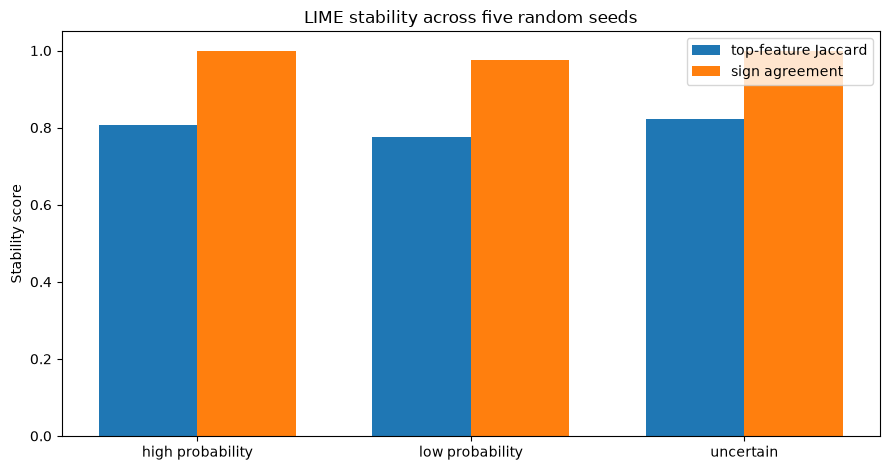

In [9]:
train_30 = training_rows.loc[training_rows["eligible_30s"].eq(1)]
train_30_transformed = context_30["preprocessing"].transform(train_30[features_c])
transformed_names_30 = context_30["preprocessing"].get_feature_names_out()

lime_rows = []
for case_index, case in enumerate(selected_cases.to_dict("records")):
    for lime_seed in LIME_SEEDS:
        explanation_table = lime_explanation_table(
            context_30["forest"],
            train_30_transformed,
            case_30_transformed[case_index],
            transformed_names_30,
            random_seed=lime_seed,
            num_features=12,
            num_samples=2500,
        )
        explanation_table["horizon_seconds"] = 30
        explanation_table["case_type"] = case["case_type"]
        explanation_table["order_id"] = case["order_id"]
        explanation_table["random_seed"] = lime_seed
        lime_rows.append(explanation_table)

lime_local_explanations = pd.concat(lime_rows, ignore_index=True)

lime_stability_rows = []
for case_type, case_table in lime_local_explanations.groupby("case_type"):
    stability = lime_seed_stability(case_table, top_n=10)
    lime_stability_rows.append({"case_type": case_type, **stability})

lime_stability = pd.DataFrame(lime_stability_rows)
display(lime_stability.round(4))

lime_consensus = (
    lime_local_explanations.groupby(
        ["case_type", "order_id", "original_feature"], as_index=False
    )["lime_weight"]
    .agg(["mean", "std", "count"])
    .reset_index()
    .rename(columns={"mean": "mean_lime_weight", "std": "std_lime_weight"})
)
lime_consensus["abs_mean_lime_weight"] = lime_consensus["mean_lime_weight"].abs()

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(lime_stability))
width = 0.36
ax.bar(
    x - width / 2,
    lime_stability["mean_pairwise_top_feature_jaccard"],
    width,
    label="top-feature Jaccard",
)
ax.bar(
    x + width / 2,
    lime_stability["mean_sign_agreement"],
    width,
    label="sign agreement",
)
ax.set_xticks(x, lime_stability["case_type"].str.replace("_", " "))
ax.set_ylim(0, 1.05)
ax.set_ylabel("Stability score")
ax.set_title("LIME stability across five random seeds")
ax.legend()
fig.tight_layout()
lime_stability_figure_path = FIGURE_DIR / "brief_lime_seed_stability.png"
fig.savefig(lime_stability_figure_path, dpi=170, bbox_inches="tight")
plt.show()


## SHAP and LIME agreement

The methods use different local approximations. Agreement is summarized by top-10 original-feature overlap and sign agreement among shared features. Disagreement is expected when predictors are correlated or the local surface is nonlinear.


In [10]:
shap_lime_rows = []
for case_type in ("high_probability", "low_probability", "uncertain"):
    shap_case = shap_local_explanations.loc[
        shap_local_explanations["case_type"].eq(case_type)
    ].copy()
    lime_case = lime_consensus.loc[
        lime_consensus["case_type"].eq(case_type)
    ].copy()
    shap_top = shap_case.nlargest(10, "abs_shap")
    lime_top = lime_case.nlargest(10, "abs_mean_lime_weight")
    shap_features = set(shap_top["original_feature"])
    lime_features = set(lime_top["original_feature"])
    shared = shap_features & lime_features

    shap_sign = shap_top.set_index("original_feature")[
        "shap_probability_contribution"
    ].apply(np.sign)
    lime_sign = lime_top.set_index("original_feature")[
        "mean_lime_weight"
    ].apply(np.sign)
    sign_matches = [
        int(shap_sign[feature] == lime_sign[feature]) for feature in shared
    ]
    shap_lime_rows.append({
        "case_type": case_type,
        "top_10_overlap_count": len(shared),
        "top_10_jaccard": len(shared) / len(shap_features | lime_features),
        "shared_feature_sign_agreement": (
            float(np.mean(sign_matches)) if sign_matches else np.nan
        ),
        "shared_features": ", ".join(sorted(shared)),
    })

shap_lime_comparison = pd.DataFrame(shap_lime_rows)
display(shap_lime_comparison.round(4))


,case_type,top_10_overlap_count,top_10_jaccard,shared_feature_sign_agreement,shared_features
0,high_probability,7,0.5385,1.0,"aggressive_trade_volume_against_order_10s, fiv..."
1,low_probability,8,0.6667,1.0,"aggressive_trade_volume_against_order_10s, fiv..."
2,uncertain,8,0.6667,1.0,"market_activity_group, normalized_queue_ahead,..."


## Same-order explanation across horizons

The uncertain 30-second order is explained with the C-feature Random Forest at all three horizons. Signed SHAP contributions show how the same market state is weighted differently as the allowed waiting time changes.


,order_id,horizon_seconds,target_fill,predicted_probability,base_probability,rank,original_feature,shap_probability_contribution,abs_shap
0,ORD007710,5,0,0.21939,0.10921,1,queue_ahead_qty,0.04432,0.04432
1,ORD007710,5,0,0.21939,0.10921,2,same_price_total_qty,0.03802,0.03802
2,ORD007710,5,0,0.21939,0.10921,3,microprice,0.01161,0.01161
3,ORD007710,5,0,0.21939,0.10921,4,ask_price_l2,0.00953,0.00953
4,ORD007710,5,0,0.21939,0.10921,5,market_activity_group,-0.00901,0.00901
5,ORD007710,5,0,0.21939,0.10921,6,oriented_top_level_imbalance,0.00898,0.00898
6,ORD007710,5,0,0.21939,0.10921,7,ask_price_l5,0.00896,0.00896
7,ORD007710,5,0,0.21939,0.10921,8,trade_count_10s,-0.00868,0.00868
8,ORD007710,5,0,0.21939,0.10921,9,normalized_queue_ahead,-0.00832,0.00832
9,ORD007710,5,0,0.21939,0.10921,10,bid_price_l1,0.00709,0.00709


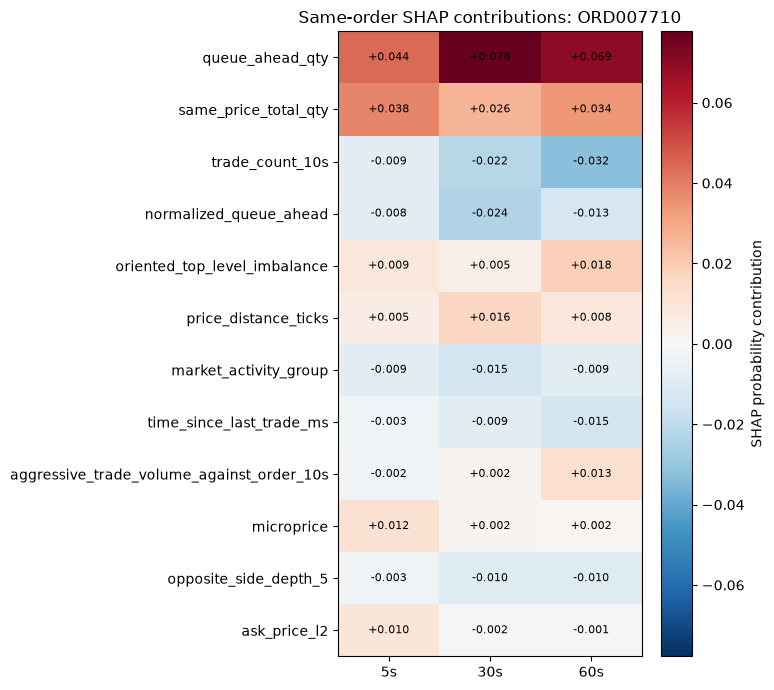

In [11]:
cross_order_id = selected_cases.loc[
    selected_cases["case_type"].eq("uncertain"), "order_id"
].iloc[0]
cross_order = validation_rows.loc[
    validation_rows["order_id"].eq(cross_order_id)
]
assert len(cross_order) == 1
assert cross_order[[f"eligible_{h}s" for h in HORIZONS]].eq(1).all(axis=None)

cross_horizon_rows = []
for horizon in HORIZONS:
    context = shap_context[horizon]
    transformed = context["preprocessing"].transform(cross_order[features_c])
    explanation = shap_explainers[horizon](transformed)
    values, base_values = positive_class_shap_values(explanation)
    aggregated = aggregate_transformed_values(
        context["mapping"],
        values[0],
        "shap_probability_contribution",
        absolute=False,
    )
    aggregated["abs_shap"] = aggregated["shap_probability_contribution"].abs()
    probability = fitted_models[
        (horizon, "C_order_lob_flow", "random_forest")
    ].predict_proba(cross_order[features_c])[:, 1][0]
    for rank, row in enumerate(
        aggregated.sort_values("abs_shap", ascending=False).itertuples(index=False),
        start=1,
    ):
        cross_horizon_rows.append({
            "order_id": cross_order_id,
            "horizon_seconds": horizon,
            "target_fill": int(cross_order[f"target_fill_{horizon}s"].iloc[0]),
            "predicted_probability": float(probability),
            "base_probability": float(base_values[0]),
            "rank": rank,
            "original_feature": row.original_feature,
            "shap_probability_contribution": row.shap_probability_contribution,
            "abs_shap": row.abs_shap,
        })

cross_horizon_explanations = pd.DataFrame(cross_horizon_rows)
display(cross_horizon_explanations.groupby("horizon_seconds").head(10).round(5))

top_cross_features = (
    cross_horizon_explanations.groupby("original_feature", as_index=False)["abs_shap"]
    .max()
    .nlargest(12, "abs_shap")["original_feature"]
)
heatmap_data = (
    cross_horizon_explanations.loc[
        cross_horizon_explanations["original_feature"].isin(top_cross_features)
    ]
    .pivot(index="original_feature", columns="horizon_seconds", values="shap_probability_contribution")
    .reindex(top_cross_features)
)

fig, ax = plt.subplots(figsize=(7.5, 7))
limit = float(np.abs(heatmap_data.to_numpy()).max())
image = ax.imshow(
    heatmap_data.to_numpy(),
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    aspect="auto",
)
ax.set_xticks(np.arange(len(HORIZONS)), [f"{h}s" for h in HORIZONS])
ax.set_yticks(np.arange(len(heatmap_data)), heatmap_data.index)
ax.set_title(f"Same-order SHAP contributions: {cross_order_id}")
for row_index in range(len(heatmap_data)):
    for column_index in range(len(HORIZONS)):
        value = heatmap_data.iloc[row_index, column_index]
        ax.text(
            column_index,
            row_index,
            f"{value:+.3f}",
            ha="center",
            va="center",
            fontsize=8,
        )
fig.colorbar(image, ax=ax, label="SHAP probability contribution")
fig.tight_layout()
cross_horizon_figure_path = FIGURE_DIR / "brief_cross_horizon_shap.png"
fig.savefig(cross_horizon_figure_path, dpi=170, bbox_inches="tight")
plt.show()


## Export brief-completion artifacts

The exports below document the remaining required analyses. None of them changes the frozen final model policy or final test results.


In [12]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

model_results_path = RESULTS_DIR / "validation_model_feature_results.csv"
rq1_path = RESULTS_DIR / "rq1_model_comparison.csv"
tree_paths_path = RESULTS_DIR / "decision_tree_paths_30s.csv"
rf_importance_path = RESULTS_DIR / "rf_impurity_permutation_comparison.csv"
rf_agreement_path = RESULTS_DIR / "rf_importance_agreement.csv"
shap_global_path = RESULTS_DIR / "shap_global_importance.csv"
shap_local_path = RESULTS_DIR / "shap_local_explanations_30s.csv"
lime_local_path = RESULTS_DIR / "lime_local_explanations_30s.csv"
lime_consensus_path = RESULTS_DIR / "lime_consensus_30s.csv"
lime_stability_path = RESULTS_DIR / "lime_stability_30s.csv"
shap_lime_path = RESULTS_DIR / "shap_lime_comparison_30s.csv"
cross_horizon_path = RESULTS_DIR / "cross_horizon_shap_explanation.csv"
summary_path = RESULTS_DIR / "brief_completion_summary.json"

validation_model_results.to_csv(model_results_path, index=False)
rq1_model_comparison.to_csv(rq1_path, index=False)
decision_tree_paths.to_csv(tree_paths_path, index=False)
rf_importance_comparison.to_csv(rf_importance_path, index=False)
rf_importance_agreement.to_csv(rf_agreement_path, index=False)
shap_global_importance.to_csv(shap_global_path, index=False)
shap_local_explanations.to_csv(shap_local_path, index=False)
lime_local_explanations.to_csv(lime_local_path, index=False)
lime_consensus.to_csv(lime_consensus_path, index=False)
lime_stability.to_csv(lime_stability_path, index=False)
shap_lime_comparison.to_csv(shap_lime_path, index=False)
cross_horizon_explanations.to_csv(cross_horizon_path, index=False)


def top_records(frame, metric, horizon, count=5):
    return (
        frame.loc[frame["horizon_seconds"].eq(horizon)]
        .nlargest(count, metric)[["original_feature", metric]]
        .to_dict("records")
    )


summary = {
    "status": "project_brief_model_and_explainability_requirements_completed",
    "analysis_source_commit": analysis_source_commit,
    "project_brief_sha256": brief_sha256,
    "raw_test_target_columns_read": False,
    "frozen_final_policy_changed": False,
    "requirements_completed": {
        "empirical_logistic_tree_forest_validation_table": True,
        "feature_sets_A_through_D": True,
        "small_decision_tree_and_market_paths": True,
        "rf_impurity_vs_permutation": True,
        "shap_global_and_three_local_cases": True,
        "lime_same_three_cases_five_random_seeds": True,
        "same_order_across_5_30_60_seconds": True,
        "shap_lime_disagreement_discussed": True,
    },
    "selected_local_cases": selected_cases[
        ["case_type", "order_id", "target_fill_30s", "rf_30_probability"]
    ].to_dict("records"),
    "lime_stability": lime_stability.to_dict("records"),
    "shap_lime_comparison": shap_lime_comparison.to_dict("records"),
    "rf_importance_agreement": rf_importance_agreement.to_dict("records"),
    "top_shap_features": {
        str(horizon): top_records(
            shap_global_importance,
            "mean_absolute_shap_probability",
            horizon,
        )
        for horizon in HORIZONS
    },
    "cross_horizon_order_id": cross_order_id,
    "limitations": [
        "SHAP and LIME explain model behavior and do not establish causality.",
        "Correlated queue and LOB variables can split or substitute importance.",
        "LIME stability is conditional on its sampling distribution and transformed feature space.",
        "All new comparisons are validation-only; the final test policy remains unchanged.",
    ],
    "artifacts": [
        model_results_path.name,
        rq1_path.name,
        tree_paths_path.name,
        rf_importance_path.name,
        rf_agreement_path.name,
        shap_global_path.name,
        shap_local_path.name,
        lime_local_path.name,
        lime_consensus_path.name,
        lime_stability_path.name,
        shap_lime_path.name,
        cross_horizon_path.name,
        tree_figure_path.name,
        rf_importance_figure_path.name,
        shap_global_figure_path.name,
        shap_local_figure_path.name,
        lime_stability_figure_path.name,
        cross_horizon_figure_path.name,
    ],
}
summary_path.write_text(json.dumps(summary, indent=2) + "\n")

print("Saved project-brief completion artifacts:")
for path in (
    model_results_path,
    rq1_path,
    tree_paths_path,
    rf_importance_path,
    rf_agreement_path,
    shap_global_path,
    shap_local_path,
    lime_local_path,
    lime_consensus_path,
    lime_stability_path,
    shap_lime_path,
    cross_horizon_path,
    summary_path,
    tree_figure_path,
    rf_importance_figure_path,
    shap_global_figure_path,
    shap_local_figure_path,
    lime_stability_figure_path,
    cross_horizon_figure_path,
):
    print(" -", path)


Saved project-brief completion artifacts:
 - /private/tmp/brief_completion_artifacts/validation_model_feature_results.csv
 - /private/tmp/brief_completion_artifacts/rq1_model_comparison.csv
 - /private/tmp/brief_completion_artifacts/decision_tree_paths_30s.csv
 - /private/tmp/brief_completion_artifacts/rf_impurity_permutation_comparison.csv
 - /private/tmp/brief_completion_artifacts/rf_importance_agreement.csv
 - /private/tmp/brief_completion_artifacts/shap_global_importance.csv
 - /private/tmp/brief_completion_artifacts/shap_local_explanations_30s.csv
 - /private/tmp/brief_completion_artifacts/lime_local_explanations_30s.csv
 - /private/tmp/brief_completion_artifacts/lime_consensus_30s.csv
 - /private/tmp/brief_completion_artifacts/lime_stability_30s.csv
 - /private/tmp/brief_completion_artifacts/shap_lime_comparison_30s.csv
 - /private/tmp/brief_completion_artifacts/cross_horizon_shap_explanation.csv
 - /private/tmp/brief_completion_artifacts/brief_completion_summary.json
 - /private

In [13]:
print("Project-brief required model and explanation analyses complete.")
for row in rf_importance_agreement.itertuples(index=False):
    print(
        f"{row.horizon_seconds:>2}s RF importance agreement | "
        f"Spearman={row.spearman_rank_correlation:.3f} | "
        f"top-10 overlap={row.top_10_overlap_count}/10"
    )
print()
for row in lime_stability.itertuples(index=False):
    print(
        f"{row.case_type:<16} LIME stability | "
        f"mean Jaccard={row.mean_pairwise_top_feature_jaccard:.3f} | "
        f"sign agreement={row.mean_sign_agreement:.3f}"
    )


Project-brief required model and explanation analyses complete.
 5s RF importance agreement | Spearman=-0.113 | top-10 overlap=3/10
30s RF importance agreement | Spearman=-0.057 | top-10 overlap=4/10
60s RF importance agreement | Spearman=0.349 | top-10 overlap=8/10

high_probability LIME stability | mean Jaccard=0.806 | sign agreement=1.000
low_probability  LIME stability | mean Jaccard=0.776 | sign agreement=0.975
uncertain        LIME stability | mean Jaccard=0.821 | sign agreement=1.000


## Next step

The required analytical track is now complete. The remaining deliverables are synthesis artifacts: a short technical report answering RQ1-RQ5 and an approximately six-slide English presentation. Survival analysis remains an optional extension and should not delay the required submission package.
